In [1]:
import pandas as pd
import numpy as np

In [2]:
df=pd.read_csv("data.csv")

In [4]:
print("First five records:")
print(df.head())

First five records:
  Shipment_ID  Distance_KM  Delivery_Time_Hours  Transportation_Cost  \
0      SHP001          168                14.02                745.6   
1      SHP002           67                 5.55                364.4   
2      SHP003          178                10.45               1982.4   
3      SHP004          113                 6.40                509.2   
4      SHP005           64                 5.11                794.0   

   Shipment_Weight_KG Vehicle_Type Traffic_Condition Weather_Condition  \
0                  59         Bike              High             Rainy   
1                 116         Bike              High             Clear   
2                 381        Truck               Low            Cloudy   
3                  18         Bike               Low             Clear   
4                 260        Truck               Low            Cloudy   

  Delivery_Status  
0         On-Time  
1         On-Time  
2         On-Time  
3         On-Time  
4 

In [5]:
print("Dataset shape:")
print(df.shape)

Dataset shape:
(50, 9)


In [6]:
print("Column information:")
print(df.info())

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Shipment_ID          50 non-null     object 
 1   Distance_KM          50 non-null     int64  
 2   Delivery_Time_Hours  50 non-null     float64
 3   Transportation_Cost  50 non-null     float64
 4   Shipment_Weight_KG   50 non-null     int64  
 5   Vehicle_Type         50 non-null     object 
 6   Traffic_Condition    50 non-null     object 
 7   Weather_Condition    50 non-null     object 
 8   Delivery_Status      50 non-null     object 
dtypes: float64(2), int64(2), object(5)
memory usage: 3.6+ KB
None


In [7]:
print("Statistical summary:")
print(df.describe())

Statistical summary:
       Distance_KM  Delivery_Time_Hours  Transportation_Cost  \
count    50.000000            50.000000             50.00000   
mean    135.920000             9.361600           1154.95200   
std      70.848744             4.029007            645.31231   
min       9.000000             1.550000            136.60000   
25%      68.250000             5.912500            746.00000   
50%     141.000000             8.650000            926.00000   
75%     194.250000            12.512500           1605.55000   
max     250.000000            16.590000           2630.40000   

       Shipment_Weight_KG  
count           50.000000  
mean           223.280000  
std            142.923276  
min              2.000000  
25%             91.750000  
50%            210.000000  
75%            348.000000  
max            469.000000  


In [8]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
Shipment_ID            0
Distance_KM            0
Delivery_Time_Hours    0
Transportation_Cost    0
Shipment_Weight_KG     0
Vehicle_Type           0
Traffic_Condition      0
Weather_Condition      0
Delivery_Status        0
dtype: int64


In [10]:
print("Duplicate rows:")
print(df.duplicated().sum())

Duplicate rows:
0


In [11]:
print("Duplicate shipment IDs:")
print(df["Shipment_ID"].duplicated().sum())

Duplicate shipment IDs:
0


In [12]:
# Create a separate copy
clean_data = df.copy()

In [13]:

# Remove duplicate rows
clean_data = clean_data.drop_duplicates()

In [14]:
# Remove records without a shipment ID
clean_data = clean_data.dropna(subset=["Shipment_ID"])


In [16]:
# Convert numerical columns to numeric format
numeric_columns = [
    "Distance_KM",
    "Shipment_Weight_KG",
    "Delivery_Time_Hours",
    "Transportation_Cost"
]

for column in numeric_columns:
    clean_data[column] = pd.to_numeric(
        clean_data[column], errors="coerce"
    )

In [17]:
# Fill missing numerical values with their column median
for column in numeric_columns:
    clean_data[column] = clean_data[column].fillna(
        clean_data[column].median()
    )

In [22]:
# Standardize text values
categorical_columns = [
    "Vehicle_Type",
    "Traffic_Condition",
    "Weather_Condition",
    "Delivery_Status"
]

for column in categorical_columns:
    clean_data[column] = (
        clean_data[column]
        .astype("string")
        .str.strip()
        .str.title()
    )

print("Categorical columns cleaned successfully!")
print(clean_data[categorical_columns].head())

Categorical columns cleaned successfully!
  Vehicle_Type Traffic_Condition Weather_Condition Delivery_Status
0         Bike              High             Rainy         On-Time
1         Bike              High             Clear         On-Time
2        Truck               Low            Cloudy         On-Time
3         Bike               Low             Clear         On-Time
4        Truck               Low            Cloudy         On-Time


In [23]:
import matplotlib.pyplot as plt

In [24]:
numeric_columns = [
    "Distance_KM",
    "Shipment_Weight_KG",
    "Delivery_Time_Hours",
    "Transportation_Cost"
]

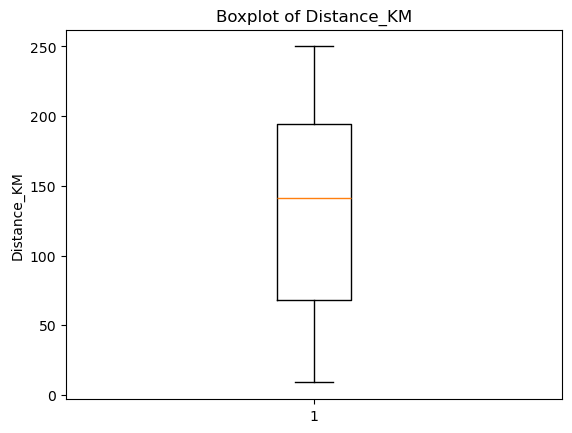

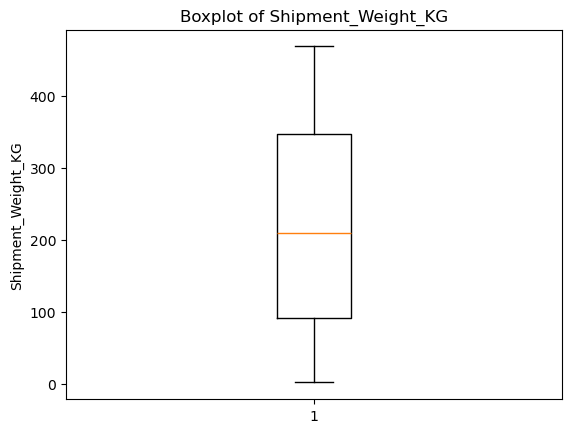

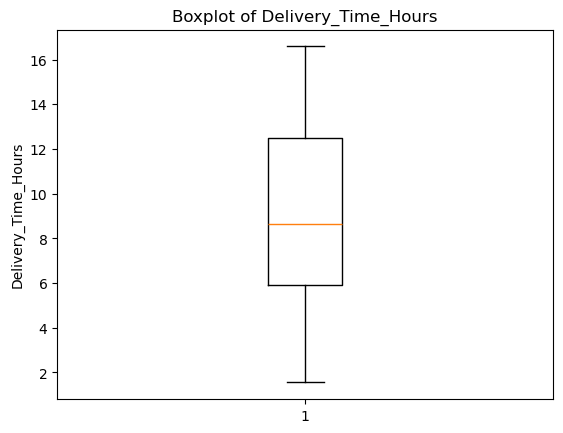

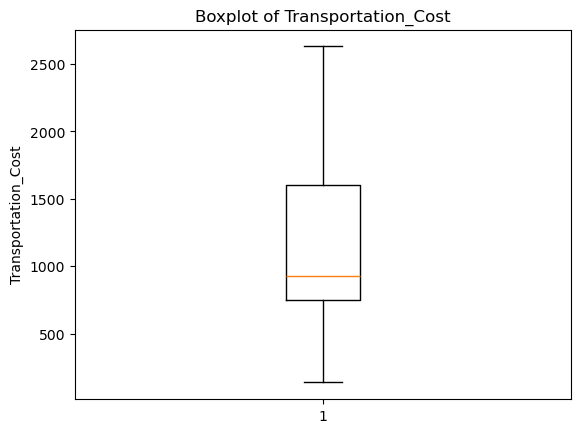

In [25]:
for column in numeric_columns:
    plt.boxplot(clean_data[column].dropna())
    plt.title("Boxplot of " + column)
    plt.ylabel(column)
    plt.show()

In [26]:
#Finding outliers
for column in numeric_columns:
    Q1 = clean_data[column].quantile(0.25)
    Q3 = clean_data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = clean_data[
        (clean_data[column] < lower_limit) |
        (clean_data[column] > upper_limit)
    ]

    print(column, "outliers:", len(outliers))

Distance_KM outliers: 0
Shipment_Weight_KG outliers: 0
Delivery_Time_Hours outliers: 0
Transportation_Cost outliers: 0


In [27]:
#Printing Clean CSV
clean_data.to_csv(
    "cleaned_logistics_data.csv",
    index=False
)

print("Cleaned dataset saved successfully!")
print("Final dataset shape:", clean_data.shape)
print("Missing values:")
print(clean_data.isnull().sum())
print("Duplicate rows:", clean_data.duplicated().sum())

Cleaned dataset saved successfully!
Final dataset shape: (50, 9)
Missing values:
Shipment_ID            0
Distance_KM            0
Delivery_Time_Hours    0
Transportation_Cost    0
Shipment_Weight_KG     0
Vehicle_Type           0
Traffic_Condition      0
Weather_Condition      0
Delivery_Status        0
dtype: int64
Duplicate rows: 0
